# now_verif — 여태 세운 가설을 펌프 14대 전체로 검증 (Auto-Cal 전후 중심)

`I1_FT_SV_괴리_원인규명_9월29일.ipynb` · `now_vis.ipynb` 의 가설은 대부분 **P1 / I1 한 쌍**으로 세웠다.
여기서는 `extract_pump_cache.py` 로 받아 둔 **14대 × 09-10 ~ 10-07** 캐시와 `build_pump_features.py` 의 사이클 표로
같은 가설이 다른 헤드·탱크에서도 성립하는지 본다. 축은 **Auto-Cal 이 있었던 시점**(HD1 만 3번)이다.

| 가설 | 내용 | 출처 |
|---|---|---|
| **H1** | Hz/SV 매핑은 Auto-Cal 때만 바뀐다 (그 밖엔 고정) | I1 노트북 §2, now_vis §2 |
| **H2** | Auto-Cal 은 Hz/SV 를 바꾸고 FT/SV 를 따라 바꾼다. 펌프 고유값(FT/Hz, 펌프 잔차)은 그대로 | now_vis §3 |
| **H3** | 배관(K) 변화와 펌프(잔차) 변화는 따로 움직인다 → 둘을 나눠 보면 원인 위치가 갈린다 | I1 노트북 §8 |
| **H4** | 기준선 형태: 폴리올은 Hz 2차식(+점도), ISO 는 누설 직선(PT/Hz/μ) | now_vis §5 |
| **H5** | 온도는 점도(Andrade)로 들어간다 → 탱크마다 B 를 추정하면 **원료의 정체**가 나올 수 있다 | I1 노트북 §11 |

## 결론 요약

| 가설 | 판정 | 근거 (절) |
|---|---|---|
| H1 | **성립 (14대)** | (SV,Hz) 매핑이 바뀐 날은 HD1 Auto-Cal 날뿐(P1·I1 9/28 100%·9/30 약 45%, P2·I2 10/5 약 55%). 나머지 10대는 4주 내내 0%. 예외는 I3 의 **레시피 하나짜리 미세 Hz 조정**(0.2~0.7%) 4번(9/18·9/29·10/2·10/7) — §2 |
| H2 | **성립 + 보강** | Auto-Cal 은 **그 순간 FT/SV 를 1 로 맞추도록 Hz 표를 다시 쓴다.** 폴리올(P1): Hz/SV 와 FT/SV 가 같은 만큼(+1.2/−0.6%) 움직이고 FT/Hz 는 0.0%. **ISO(I1·I2): FT/SV 변화 −0.4 / 0.0 / 0.0% — 그 사이 배관 K 가 +14 / −20 / +5% 바뀐 것을 Hz/SV(+2.7 / −5.1 / +1.0%)로 흡수했다.** 예외는 P2(10/5): FT/Hz +0.9%, 사흘째에도 반쯤 남음 — PLC 로직으로는 설명 안 됨(판정 보류) — §3 |
| H3 | **성립 + 실례 1건** | K 는 I1 −11~+25%, I6 −24~+55%, I7 +14% 대(9/21~), I3 −5~−8%(9/18~) 로 크게 움직이는데 펌프 잔차는 일별 ±1.4% 안(연휴 중 9/27 제외). **9/17 P7 유량계 고장(4시간 FT≈0, 압력은 정상)** 이 "센서 고장 = 두 지표가 함께" 서명 그대로 잡힌다 — §4 |
| H4 | **조건부 성립** | ISO 는 7대 중 6대에서 누설식이 가장 좁다(I1 1.5→0.54%, I2 2.5→1.0%). 폴리올 2차식은 레시피 의존(η²)을 크게 줄인다(P1 0.66→0.07, P6 0.49→0.01). 단 펌프 기종이 펌프마다 달라(1 Hz 당 유량 0.25~0.84) **기준선은 펌프별로 따로** 맞춰야 한다 — §5 |
| H5 | **부분 성립 — 원료 이름까지는 못 간다** | 탱크 온도가 2~3℃ 안으로 관리돼 B 는 I1 에서만 식별(750~1500 K, 원료표 TM-20 1921 과 같은 자릿수). **같은 기종(I1·I2)끼리 누설을 비교하면 Tank 3 ISO 는 TM-20 보다 묽거나(점도 약 1/2) I2 가 더 닳았다** — 2013 원료표의 MC-70(TM-20 의 2.3배 점도)과는 반대 방향. 헤드별 ISO/POL 비는 같은 원료 계통끼리 일치(BACK 0.47·0.46, CUSH 0.48·0.49) — §6 |

**같이 나온 것 — 전처리기를 고쳤다** (§1, §7)

- HD2(P3·I3) 는 사출이 대표 Hz 구간을 거의 다 덮고(대표 레시피는 Hz 3단), HD3-2(P6·I6) 는 켜짐이 7~9틱으로 짧다 → HD1 기준 "사출 전 안정 구간" 정의로는 사이클 대부분이 버려졌다(P3 272개).
  사출 중 안정 틱으로 대신하고 `steady_src` 로 표시 → P3 8,187개 · P6 9,626개.
- 순환운전 Hz 는 펌프마다 다르다 (P1·I1 20, I7 30, 나머지 25 Hz) → 설정에 `circ_hz`.
- 기준선 학습에 이상치 제거(2단계 최소제곱) — P7 기준 주의 고장 사이클이 계수를 +3.7% 끌고 갔다.
- `ft_timeout`(3초 안에 SV±3%) 은 개루프 펌프에선 **평소에도** 울린다(I1 하루 420건, P2 690건) → 펌프별 기준이 필요.

---
## §0. 준비

- 사이클 표: `cache/pump_feat/{펌프}_cycles.pkl.xz` (`build_pump_features.py`, 전처리기 `run()` 그대로). 기준선은 여기서 맞춘다.
- 펌프마다 **주된 안정 구간 출처**(`steady_src` 가 절반 넘는 쪽)만 쓴다 — clean(사출 전) 과 shot(사출 중) 은 PT·K 수준이 달라 섞지 않는다.
- 기준 주 **REF = 09-14 ~ 09-19** (Auto-Cal 전, 연휴 전).
- 원료 점도 B 는 `pump_settings.json` 값 — P1(TM-337)·I1(TM-20) 만 검증, 나머지는 이름·탱크로 넣은 임시값.

In [1]:
import os, sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib, matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D

ROOT_DIR = os.path.abspath(os.getcwd())
sys.path.insert(0, os.path.join(ROOT_DIR, "HDI_MODEL"))
matplotlib.rcParams["font.family"] = "AppleGothic"
matplotlib.rcParams["axes.unicode_minus"] = False
matplotlib.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
warnings.simplefilter("ignore", RuntimeWarning)

from build_pump_features import load_feat, FEAT_DIR
from extract_pump_cache import ORDER, load_day
from new_pump_preprocessor import (PumpSetup, PumpBaseline, add_baseline_features, load_settings,
                                   pump_tags, mu_rel, _robust_lstsq)

S = load_settings()
REF = ("2026-09-14", "2026-09-20")
AUTOCAL = pd.DataFrame([("P1", "2026-09-27 11:40"), ("I1", "2026-09-27 11:40"), ("P1", "2026-09-30 15:27"),
                        ("I1", "2026-09-30 15:27"), ("P2", "2026-10-05 15:00"), ("I2", "2026-10-05 15:00")],
                       columns=["pump", "time"]).assign(time=lambda d: pd.to_datetime(d.time))

SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, CRITICAL = "#2a78d6", "#eb6834", "#1baf7a", "#d03b3b"


def style_ax(ax, grid="y"):
    ax.set_facecolor(SURFACE)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(AXIS)
    ax.tick_params(colors=INK2, labelsize=8)
    if grid:
        ax.grid(axis=grid, color=GRID, linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)


def main_src(c):
    return "clean" if (c.steady_src == "clean").mean() > 0.5 else "shot"


def cycles(p, single_hz=False):
    """주된 안정 출처의 사이클만. single_hz=True 면 Hz 한 단계짜리만 (HD2 다단 제외)."""
    c = load_feat(p)
    c = c[c.steady_src == main_src(c)].dropna(subset=["FT", "PT", "Hz"]).copy()
    if single_hz:
        c = c[c.n_hz_levels == 1]
    c["day"] = c.t_start.dt.normalize()
    return c


def class_norm(c, col, ref):
    """사이클 값 / 기준 구간 같은 SV 클래스 중앙값 − 1 (%). 기준에 없던 클래스는 NaN."""
    med = ref.groupby("SV_class")[col].median()
    return (c[col] / c.SV_class.map(med) - 1) * 100


def with_baseline(p, c=None, ref=REF):
    """REF 로 기준선을 맞추고 pump_resid · r_phys · 클래스 정규화 변화율을 붙인다."""
    c = cycles(p) if c is None else c
    r = c[(c.t_start >= ref[0]) & (c.t_start < ref[1])]
    base = PumpBaseline.fit(r, PumpSetup(p, S, allow_unverified=True))
    c = add_baseline_features(c, base)
    for col, name in [("K", "K_chg"), ("FT_SV", "FTSV_chg"), ("Hz_SV", "HzSV_chg"), ("FT_Hz", "FTHz_chg")]:
        c[name] = class_norm(c, col, r)
    return c, base


log = pd.read_csv(os.path.join(FEAT_DIR, "_build_log.csv")).drop_duplicates("pump", keep="last").set_index("pump")
log[["days", "ticks", "cycles", "circ_windows", "alerts", "material", "verified"]].loc[ORDER]

,days,ticks,cycles,circ_windows,alerts,material,verified
pump,,,,,,,
P1,2026-09-10~2026-10-07,3985467,59496,4448,2,TM-337,True
I1,2026-09-10~2026-10-07,3962013,59498,4448,9246,TM-20,True
P2,2026-09-10~2026-10-07,4038346,60629,4450,15178,AM-315,False
I2,2026-09-10~2026-10-07,3964740,60334,4450,3009,ISO-GENERIC,False
P3,2026-09-10~2026-10-07,3972645,8187,4448,126,POL-GENERIC,False
I3,2026-09-10~2026-10-07,4002077,8185,4448,139,ISO-GENERIC,False
P4,2026-09-10~2026-10-07,4038253,5814,4448,0,POL-GENERIC,False
I4,2026-09-10~2026-10-07,4036873,5814,4448,0,ISO-GENERIC,False
P5,2026-09-10~2026-10-07,3908390,24893,4448,22,MBR-360,False


---
## §1. 먼저 — 헤드마다 사이클 구조가 다르다

HD1(P1·I1) 기준으로 만든 사이클 정의가 다른 헤드에도 맞는지부터 본다. 09-15 하루, 펌프별 대표 Hz 클래스의 **틱별 평균 파형**.

In [2]:
rows = []
for p in ORDER:
    c = load_feat(p)
    st = PumpSetup(p, S, allow_unverified=True)
    prod_days = c.t_start.dt.normalize().nunique()
    rows.append({"펌프": p, "이름": S["pumps"][p]["name"], "탱크": S["pumps"][p]["tank"],
                 "헤드/슬롯": f'{S["pumps"][p]["head"]}/{S["pumps"][p]["slot"]}',
                 "사이클/일": round(len(c) / prod_days), "켜짐 틱 중앙": c.n_ticks.median(),
                 "Hz 다단 %": round((c.n_hz_levels > 1).mean() * 100, 1),
                 "안정=사출중 %": round((c.steady_src == "shot").mean() * 100, 1),
                 "순환 Hz": st.circ_hz / 100, "FT/Hz 중앙": round(c.FT_Hz.median(), 3)})
struct = pd.DataFrame(rows).set_index("펌프")
struct

,이름,탱크,헤드/슬롯,사이클/일,켜짐 틱 중앙,Hz 다단 %,안정=사출중 %,순환 Hz,FT/Hz 중앙
펌프,,,,,,,,,
P1,1펌프 BACK,P1,HD1/1,2704,16.0,4.8,6.6,20.0,0.634
I1,1펌프 ISO,I1,HD1/1,2704,15.0,4.8,6.8,20.0,0.349
P2,1-2펌프 CUSH,P5,HD1/2,2756,16.0,35.7,20.1,25.0,0.489
I2,1-2펌프 ISO,I3,HD1/2,2742,16.0,35.5,22.7,25.0,0.312
P3,2-1펌프 SOFT,P2,HD2/1,390,15.0,29.8,96.7,25.0,0.816
I3,2-1펌프 MDI,I2,HD2/1,390,14.0,29.8,96.7,25.0,0.430
P4,2-2펌프 HARD,P4,HD2/2,277,13.0,4.6,3.1,25.0,0.836
I4,2-2펌프 MDI,I2,HD2/2,277,13.0,4.5,2.7,25.0,0.393
P5,3펌프 고탄성,P3,HD3/1,1185,13.0,2.5,50.1,25.0,0.665


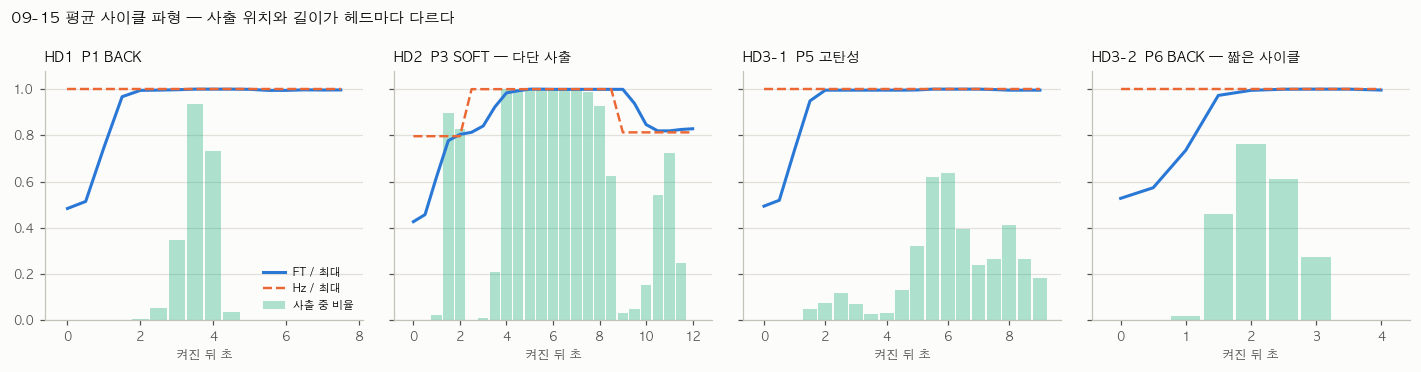

In [3]:
def mean_wave(p, day="2026-09-15"):
    t = pump_tags(p, S)
    d = load_day(p, day).select_dtypes("number").astype("float64").ffill()
    bu = d[t["bu"]].fillna(0)
    grp = (bu.diff() > 0).cumsum()
    on = d[bu > 0].copy()
    on["k"] = on.groupby(grp[bu > 0]).cumcount()
    on["hz_mode"] = on.groupby(grp[bu > 0])[t["hz"]].transform(lambda x: x.mode()[0])
    o = on[on.hz_mode == on.hz_mode.mode()[0]]
    w = o.groupby("k").agg(n=(t["ft"], "size"), hz=(t["hz"], "median"), ft=(t["ft"], "median"),
                           pt=(t["pt"], "median"), shot=(t["shot"], "mean"))
    return w[w.n >= w.n.max() * 0.2]


fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), sharey=True, facecolor=SURFACE)
for ax, (p, ttl) in zip(axes, [("P1", "HD1  P1 BACK"), ("P3", "HD2  P3 SOFT — 다단 사출"),
                               ("P5", "HD3-1  P5 고탄성"), ("P6", "HD3-2  P6 BACK — 짧은 사이클")]):
    w = mean_wave(p)
    x = w.index * 0.5
    ax.bar(x, w.shot, width=0.45, color=AQUA, alpha=0.35, zorder=2, label="사출 중 비율")
    ax.plot(x, w.ft / w.ft.max(), color=BLUE, lw=2, zorder=3, label="FT / 최대")
    ax.plot(x, w.hz / w.hz.max(), color=ORANGE, lw=1.6, ls="--", zorder=3, label="Hz / 최대")
    style_ax(ax)
    ax.set_title(ttl, loc="left", color=INK, fontsize=9, fontweight="bold")
    ax.set_xlabel("켜진 뒤 초", color=INK2, fontsize=8)
axes[0].set_ylim(0, 1.08)
axes[0].legend(fontsize=7, frameon=False, loc="lower right")
fig.suptitle("09-15 평균 사이클 파형 — 사출 위치와 길이가 헤드마다 다르다", x=0.01, ha="left", color=INK, fontsize=10)
fig.tight_layout()
plt.show()

**읽기**

- **HD1(P1)**: 3초쯤 사출이 짧게(2~3틱) 끼고, 그 앞뒤로 사출 없는 안정 구간이 충분하다 — 지금 정의가 맞는 구조.
- **HD2(P3·I3)**: 대표 레시피는 사이클 안에서 **Hz 가 3단**(앞 단 → 본 사출 단 → 뒷 단)으로 바뀌고, 본 사출이 대표 Hz 구간을 거의 다 덮는다
  (안정 구간의 97% 가 사출 중). 사출 전 안정 구간이 없어 예전 정의로는 사이클 272개만 남았다.
- 사이클 안에서 Hz 가 바뀌는 사이클은 HD2 만이 아니다 — **P2·I2 36%, P7·I7 52%, P3·I3 30%**, 나머지는 10% 이하.
  다단 사출 레시피를 헤드마다 다르게 쓰고 있다. 아래 H1~H5 에서 Hz 기준 비교는 Hz 한 단계짜리 사이클만 쓴다.
- **HD3-2(P6·I6)**: 켜짐이 7~9틱으로 짧다. 기본값(Hz 바뀐 뒤 5틱 이후, 최소 8틱)이면 절반 가까이 버려졌다 — FT 는 4틱째 이미 99%.
- **순환 Hz** 도 펌프마다 다르다(표). 20 Hz 고정이었던 탓에 P2 이후 펌프의 순환창이 0개였다.

**전처리기 반영** (`new_pump_preprocessor.py`, `make_pump_settings.py`)

| 바꾼 것 | 내용 |
|---|---|
| `steady_src` | 사출 전 안정 틱이 3개 미만이면 **사출 중 안정 틱**으로 대신하고 `"shot"` 으로 표시. PT·K 는 노즐이 열린 상태라 clean 과 섞지 말 것 |
| `n_hz_levels` | 사이클 안 Hz 단계 수 (다단 사출 레시피 구분용) |
| `circ_hz` | 펌프별 순환 Hz (설정 `CIRC_HZ_OF`). 날마다 100% 같은 값 |
| `PARAM_OVERRIDES` | P6·I6: `STEADY_MIN` 4, `MIN_CYCLE_TICKS` 7 |

clean 사이클 값은 바꾸기 전과 **비트 단위로 같다**(P1 55,598개 비교).

---
## §2. H1 — Hz/SV 매핑은 Auto-Cal 때만 바뀌나

PLC 에서 Hz = SV × 구간계수(`Cal_Scale_Buff_*`) × `A_CAL_g_SV_Gain`. 같은 SV 라도 레시피마다 Hz 가 2~3개 있다
(P1 ±0.25%, I1 ±1.4% — 레시피별 보정). 그래서 "Hz/SV 가 바뀌었나" 는 **전 생산일에도 있던 SV 인데 (SV, Hz) 쌍이 처음 보이는 사이클 비율**로 본다.
새 SV(새 레시피)는 따로 센다.

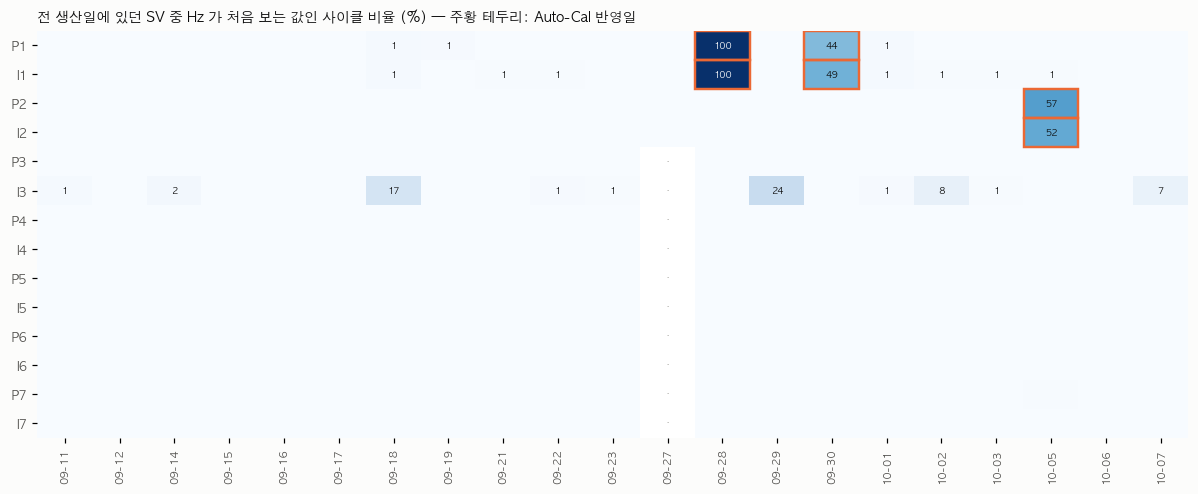

In [4]:
def mapping_change(c):
    out, prev_pairs, prev_sv = [], None, None
    for d, g in c.groupby("day"):
        pairs = list(zip(g.SV_class, g.Hz))
        if prev_pairs is not None:
            seen = g.SV_class.isin(prev_sv).to_numpy()
            newpair = np.array([pp not in prev_pairs for pp in pairs])
            out.append({"day": d, "map_chg": (newpair & seen).sum() / max(seen.sum(), 1) * 100,
                        "new_sv": (~seen).mean() * 100})
        prev_pairs, prev_sv = set(pairs), set(g.SV_class)
    return pd.DataFrame(out).set_index("day")


CYC = {p: cycles(p) for p in ORDER}
MAP = {p: mapping_change(CYC[p]) for p in ORDER}
H1 = pd.DataFrame({p: MAP[p].map_chg for p in ORDER}).T
H1.columns = [d.strftime("%m-%d") for d in H1.columns]


def heat(ax, M, vmax, cmap, fmt="{:.0f}", center=None):
    v = M.to_numpy(float)
    vmin = -vmax if center == 0 else 0
    ax.imshow(np.clip(v, vmin, vmax), cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    for i in range(v.shape[0]):
        for j in range(v.shape[1]):
            if np.isfinite(v[i, j]) and abs(v[i, j]) >= (0.5 if center is None else 0.05):
                ax.text(j, i, fmt.format(v[i, j]), ha="center", va="center", fontsize=6,
                        color="white" if abs(v[i, j]) > vmax * 0.6 else INK)
            elif not np.isfinite(v[i, j]):
                ax.text(j, i, "·", ha="center", va="center", fontsize=7, color=MUTED)
    ax.set_xticks(range(M.shape[1]), M.columns, fontsize=7, rotation=90, color=INK2)
    ax.set_yticks(range(M.shape[0]), M.index, fontsize=8, color=INK2)
    for s in ax.spines.values():
        s.set_visible(False)


fig, ax = plt.subplots(figsize=(11, 4.6), facecolor=SURFACE)
heat(ax, H1, 100, "Blues")
for _, e in AUTOCAL.iterrows():
    d = e.time.normalize() + (pd.Timedelta(days=1) if e.time.hour >= 11 and e.time.day == 27 else pd.Timedelta(0))
    lbl = d.strftime("%m-%d")
    if lbl in H1.columns:
        ax.add_patch(plt.Rectangle((list(H1.columns).index(lbl) - 0.5, ORDER.index(e.pump) - 0.5), 1, 1,
                                   fill=False, ec=ORANGE, lw=1.6))
ax.set_title("전 생산일에 있던 SV 중 Hz 가 처음 보는 값인 사이클 비율 (%) — 주황 테두리: Auto-Cal 반영일",
             loc="left", color=INK, fontsize=9)
fig.tight_layout()
plt.show()

In [5]:
# 예외: I3 — 어떤 SV 의 Hz 가 바뀌었나
def new_pairs(c, d0, d1):
    a, b = c[c.day == d0], c[c.day == d1]
    pa, sva = set(zip(a.SV_class, a.Hz)), set(a.SV_class)
    nb = b[[(s, h) not in pa and s in sva for s, h in zip(b.SV_class, b.Hz)]]
    g = nb.groupby(["SV_class", "Hz"]).agg(n=("FT", "size"), 처음=("t_start", "min")).reset_index()
    g["전날 Hz"] = [sorted(a[a.SV_class == s].Hz.unique().astype(int).tolist()) for s in g.SV_class]
    g["날"] = d1
    return g

days = sorted(CYC["I3"].day.unique())
pd.concat([new_pairs(CYC["I3"], days[i - 1], days[i]) for i, d in enumerate(days)
           if i and H1.loc["I3"].get(pd.Timestamp(d).strftime("%m-%d"), 0) >= 5])

,SV_class,Hz,n,처음,전날 Hz,날
0,1300.0,3021.0,66,2026-09-18 12:02:31.035347,"[3015, 3024, 3036]",2026-09-18
0,1300.0,3024.0,2,2026-09-29 10:36:30.190312,"[3015, 3036]",2026-09-29
1,1450.0,3373.0,70,2026-09-29 10:32:49.295916,[3363],2026-09-29
2,1450.0,3387.0,1,2026-09-29 17:41:27.637743,[3363],2026-09-29
0,1450.0,3373.0,45,2026-10-02 12:04:41.858814,"[3363, 3387]",2026-10-02
0,1300.0,3024.0,10,2026-10-07 15:40:28.604383,"[3015, 3036]",2026-10-07
1,1450.0,3373.0,10,2026-10-07 15:40:14.646703,"[3363, 3387]",2026-10-07


**판정: 성립.**

- (SV, Hz) 매핑이 바뀐 날은 **HD1 의 Auto-Cal 날뿐**이다 — P1·I1: 9/27 11:40 Auto-Cal → 9/28 100%, 9/30 15:27 → 그날 오후분 약 45%.
  P2·I2: 10/5 15:00 → 약 55%. **나머지 10대는 4주 동안 한 번도 바뀌지 않았다.**
- 예외 I3 는 SV 두 개(1300, 1450)의 Hz 가 몇 개 값(3015/3021/3024/3036, 3363/3373/3387) 사이를 0.2~0.7% 오간 것 —
  표 전체를 다시 쓰는 Auto-Cal 이 아니라 **레시피 단위 미세 조정**이다(Calibration.il 의 `A_CAL_g_SV_Gain × D00336`,
  시험 사출 무게로 맞추는 Gain Set 경로로 추정. 레시피별로 값이 갈리는 이유는 IL 만으로는 확인 못 함).
- 실무 함의: **Hz/SV 가 바뀐 사이클은 "보정 이벤트" 로 기록**하면 된다(Auto-Cal_Done 태그 없이도 데이터에서 잡힌다). 기준선은 Hz 기준이라 영향받지 않는다.

---
## §3. H2 — Auto-Cal 이 바꾸는 것과 안 바꾸는 것

- Hz/SV · FT/SV · FT/Hz · K: 직후 구간 값을 **직전 생산 구간의 같은 SV 클래스 중앙값**과 비교(레시피 구성 차이 제거).
- 펌프 잔차: **REF 주(09-14~19) 기준선** — 이벤트와 무관한 고정 기준. (직전 구간으로 맞추면 압력 범위가 좁아 ISO 누설식이 외삽된다.)

In [6]:
EVW = {  # 이벤트: (직전 시작, 이벤트, 직후 끝) — 직후 구간은 다음 Auto-Cal 전까지
    ("P1", "09-27"): ("2026-09-21", "2026-09-27 11:40", "2026-09-30 15:27"),
    ("I1", "09-27"): ("2026-09-21", "2026-09-27 11:40", "2026-09-30 15:27"),
    ("P1", "09-30"): ("2026-09-28", "2026-09-30 15:27", "2026-10-04"),
    ("I1", "09-30"): ("2026-09-28", "2026-09-30 15:27", "2026-10-04"),
    ("P2", "10-05"): ("2026-09-30", "2026-10-05 15:00", "2026-10-08"),
    ("I2", "10-05"): ("2026-09-30", "2026-10-05 15:00", "2026-10-08"),
}
BL = {p: with_baseline(p, CYC[p]) for p in ORDER}      # REF 기준선 — §4 에서도 쓴다
rows, HOURLY = [], {}
for (p, lbl), (a, t, b) in EVW.items():
    c = BL[p][0][BL[p][0].n_hz_levels == 1]
    t = pd.Timestamp(t)
    pre, post = c[(c.t_start >= a) & (c.t_start < t)], c[(c.t_start > t) & (c.t_start < b)]
    cc = pd.concat([pre, post]).copy()
    for col, name in [("K", "K_chg"), ("FT_SV", "FTSV_chg"), ("Hz_SV", "HzSV_chg"), ("FT_Hz", "FTHz_chg")]:
        cc[name] = class_norm(cc, col, pre)
    po = cc[cc.t_start > t]
    rows.append({"펌프": p, "Auto-Cal": lbl, "직전 사이클": len(pre), "직후 사이클": len(post),
                 "Hz/SV %": po.HzSV_chg.median(), "FT/SV %": po.FTSV_chg.median(),
                 "FT/Hz %": po.FTHz_chg.median(),
                 "펌프 잔차 전→후 %": f"{pre.pump_resid.median():+.2f} → {po.pump_resid.median():+.2f}",
                 "K %": po.K_chg.median(), "온도 전→후": f"{pre.T_C.median():.1f}→{post.T_C.median():.1f}"})
    HOURLY[(p, lbl)] = cc.set_index("t_start")[["HzSV_chg", "FTSV_chg", "pump_resid", "K_chg"]].resample("1h").median()
H2 = pd.DataFrame(rows).set_index(["펌프", "Auto-Cal"]).round(2)
H2

,,직전 사이클,직후 사이클,Hz/SV %,FT/SV %,FT/Hz %,펌프 잔차 전→후 %,K %,온도 전→후
펌프,Auto-Cal,,,,,,,,
P1,09-27,8429,5883,1.16,1.08,-0.00,-0.05 → -0.01,-0.77,21.9→21.8
I1,09-27,8417,5840,2.69,-0.40,-3.36,+0.70 → -0.60,13.55,22.0→21.7
P1,09-30,5883,8411,-0.59,-0.56,0.05,-0.01 → +0.12,-0.41,21.8→21.8
I1,09-30,5840,8380,-5.10,0.00,5.38,-0.60 → +1.04,-20.27,21.7→21.9
P2,10-05,6965,2946,0.55,1.46,0.89,-0.62 → +0.31,4.79,20.4→20.5
I2,10-05,6625,2847,1.00,0.00,-0.98,+0.21 → +0.54,5.11,20.4→20.4


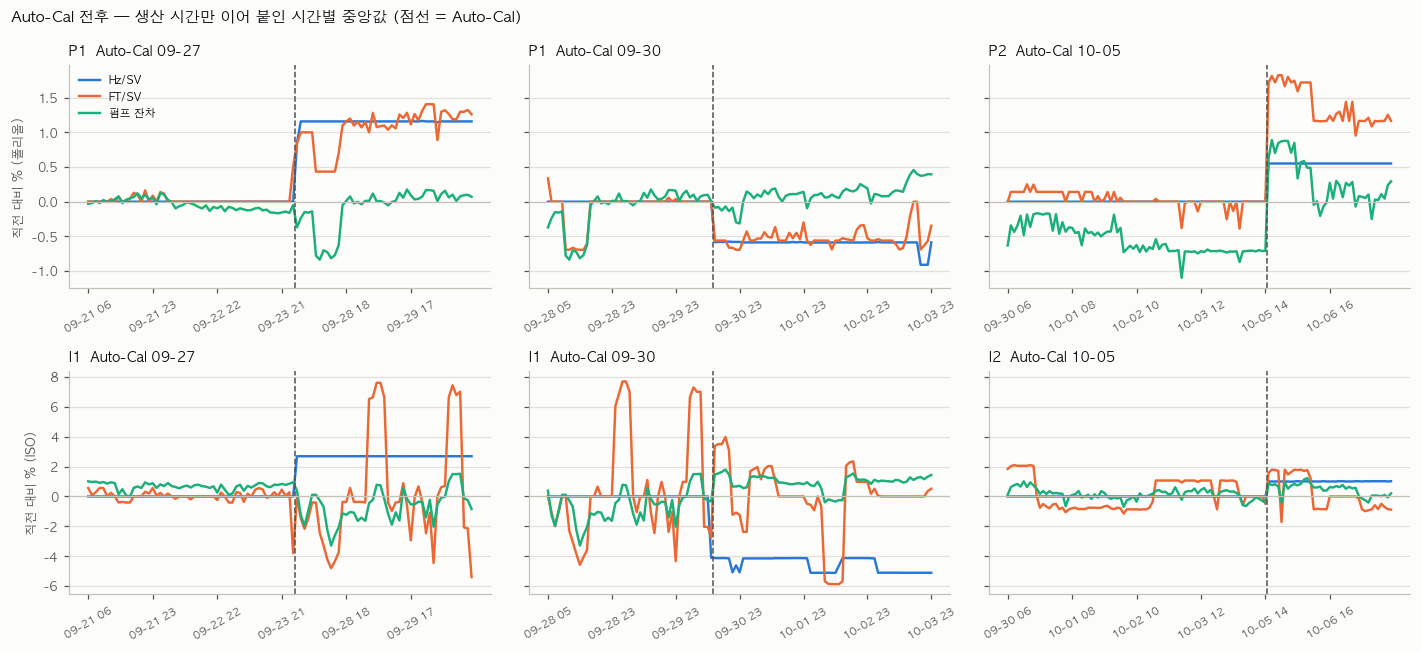

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6), facecolor=SURFACE, sharey="row")
for j, lbl in enumerate(["09-27", "09-30", "10-05"]):
    for i, kind in enumerate(["P", "I"]):
        p = (kind + ("2" if lbl == "10-05" else "1"))
        h = HOURLY[(p, lbl)].dropna(how="all")
        ax = axes[i, j]
        x = np.arange(len(h))
        ax.plot(x, h.HzSV_chg, color=BLUE, lw=1.6, label="Hz/SV")
        ax.plot(x, h.FTSV_chg, color=ORANGE, lw=1.6, label="FT/SV")
        ax.plot(x, h.pump_resid, color=AQUA, lw=1.6, label="펌프 잔차")
        t = pd.Timestamp(EVW[(p, lbl)][1])
        k = int(np.searchsorted(h.index, t))
        ax.axvline(k - 0.5, color=INK2, lw=1, ls="--")
        ax.axhline(0, color=AXIS, lw=0.8)
        style_ax(ax)
        ticks = [q for q in range(0, len(h), max(len(h) // 6, 1))]
        ax.set_xticks(ticks, [h.index[q].strftime("%m-%d %H") for q in ticks], fontsize=7, rotation=30)
        ax.set_title(f"{p}  Auto-Cal {lbl}", loc="left", color=INK, fontsize=9, fontweight="bold")
axes[0, 0].set_ylabel("직전 대비 % (폴리올)", color=INK2, fontsize=8)
axes[1, 0].set_ylabel("직전 대비 % (ISO)", color=INK2, fontsize=8)
axes[0, 0].legend(fontsize=7, frameon=False)
fig.suptitle("Auto-Cal 전후 — 생산 시간만 이어 붙인 시간별 중앙값 (점선 = Auto-Cal)", x=0.01, ha="left", color=INK, fontsize=10)
fig.tight_layout()
plt.show()

**읽기 — Auto-Cal 은 "지금 FT = SV" 가 되게 Hz 표를 다시 쓴다**

- **P1 (폴리올)**: 직전 FT/SV 가 0.99 대였고, Auto-Cal 이 Hz/SV 를 +1.2% 올리자 FT/SV 도 **같은 만큼**(+1.1%) 올라 1.00 이 됐다.
  9/30 도 −0.6 / −0.6%. FT/Hz·펌프 잔차는 0 — 폴리올은 누설이 거의 없어 FT 가 Hz 에 비례하기 때문이다. → 가설 그대로.
- **I1·I2 (ISO)**: FT/SV 변화가 **−0.4 / 0.0 / 0.0%**. 대신 Hz/SV 가 +2.7 / −5.1 / +1.0% 움직였고, 같은 구간에 **K 가 +14 / −20 / +5%**.
  9/27 은 ISO1 라인이 막혀 있던 때라 Hz 를 올렸고, 9/29 에 막힘이 풀린 뒤(I1 노트북 §5~7) 9/30 Auto-Cal 이 다시 내렸다.
  **Auto-Cal 이 배관 변화를 Hz 로 흡수**한 셈이다. FT/Hz 의 −3.4 / +5.4 / −1.0% 는 K 변화에 따른 누설 변화이고, 펌프 잔차는 ±1% 안에서 움직였다.
  - 그러므로 **Auto-Cal 직후 FT/SV 가 1 에 붙는 것은 "정상" 의 증거가 아니다** — 배관 이상을 덮었을 수도 있다. **K 와 Hz/SV 변화량을 같이** 봐야 한다.
  - I1 의 시간별 펌프 잔차는 K 가 크게 튈 때 −3% 까지 따라 움직인다(그림 아래 왼쪽). 누설식이 REF 주의 압력 범위 밖에서는 완전하지 않다 — 일 단위로는 ±1.4% 안.
- **P2 (10/5) 만 예외**: 같은 레시피·같은 온도에서 Hz +0.55% 인데 FT/SV +1.46% — **FT/Hz 가 +0.9%**(주력 레시피 기준 +1.4%) 올랐다.
  - `Hz_Out` 은 아날로그 출력값(`Ana_Out` → `_16_CH0_DATA`)을 Hz 로 되돌린 값이라 인버터 지령 그 자체다(Pump_Control.il 1905~1923, 3615). PLC 쪽으로는 설명 안 된다.
  - 아래 표처럼 **이틀 뒤에도 +0.8% 로 반쯤 남아 있다**. Auto-Cal 의 고 Hz(최대 55 Hz) 운전이 남긴 효과(흡입측 기포 배출·이물 세척 등)일 수 있지만 데이터만으로는 단정 못 한다. **판정 보류.**

In [8]:
c = CYC["P2"][CYC["P2"].n_hz_levels == 1]
pre = c[(c.t_start >= "2026-09-30") & (c.t_start < "2026-10-05 15:00")]
top = pre.SV_class.value_counts().index[:4]
d = c[c.SV_class.isin(top) & (c.t_start >= "2026-10-01")].copy()
d["구간"] = np.where(d.t_start < "2026-10-05 15:00", "Auto-Cal 전", d.t_start.dt.strftime("%m-%d") + " 후")
d.pivot_table(index="SV_class", columns="구간", values="FT_Hz", aggfunc="median").round(4)

구간,10-05 후,10-06 후,10-07 후,Auto-Cal 전
SV_class,,,,
2520.0,0.4963,0.4938,0.4933,0.4893
2780.0,0.4950,0.4917,0.4903,0.4877
2810.0,0.4952,0.4915,0.4902,0.4878
2850.0,0.4932,0.4908,0.4908,0.4865


---
## §4. H3 — 배관(K)과 펌프(잔차)는 따로 움직이나

REF 주로 기준선을 맞추고, 일별로 **K 변화(같은 SV 클래스 대비)** 와 **펌프 잔차(FT/Hz ÷ 물리 기대값)** 를 나란히 본다.
H3 가 맞다면 왼쪽은 크게 움직여도 오른쪽은 0 근처에 있어야 한다.

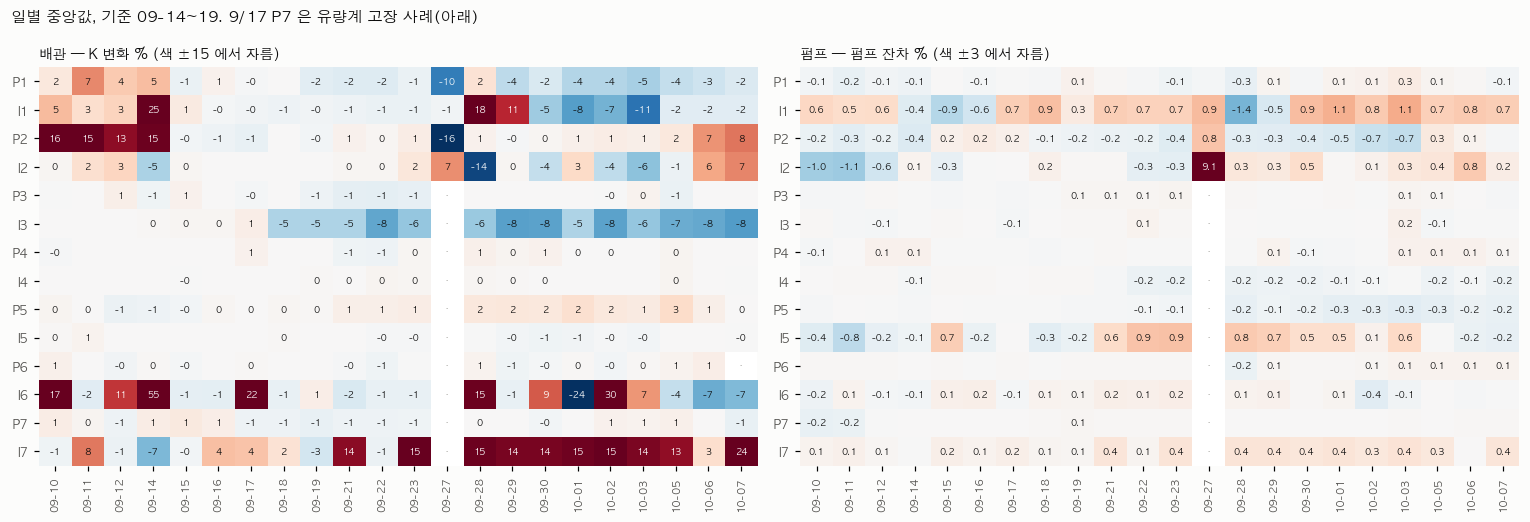

,K 일별 변화 범위 %,K |변화| 최대,펌프 잔차 |일별| 최대 %,펌프 잔차 |일별| 중앙 %
P1,-10 ~ 7,10.3,0.26,0.07
I1,-11 ~ 25,24.9,1.39,0.73
P2,-16 ~ 16,16.5,0.85,0.27
I2,-14 ~ 7,13.8,9.09,0.27
P3,-1 ~ 1,1.4,0.09,0.03
I3,-8 ~ 1,8.4,0.15,0.03
P4,-1 ~ 1,0.7,0.14,0.03
I4,-0 ~ 0,0.5,0.19,0.06
P5,-1 ~ 3,2.8,0.35,0.07
I5,-1 ~ 1,0.6,0.88,0.36


In [9]:
Kd = pd.DataFrame({p: BL[p][0].groupby("day").K_chg.median() for p in ORDER}).T
Rd = pd.DataFrame({p: BL[p][0].groupby("day").pump_resid.median() for p in ORDER}).T
Kd.columns = Rd.columns = [d.strftime("%m-%d") for d in Kd.columns]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), facecolor=SURFACE)
heat(axes[0], Kd, 15, "RdBu_r", center=0)
heat(axes[1], Rd, 3, "RdBu_r", fmt="{:.1f}", center=0)
axes[0].set_title("배관 — K 변화 % (색 ±15 에서 자름)", loc="left", color=INK, fontsize=9)
axes[1].set_title("펌프 — 펌프 잔차 % (색 ±3 에서 자름)", loc="left", color=INK, fontsize=9)
fig.suptitle("일별 중앙값, 기준 09-14~19. 9/17 P7 은 유량계 고장 사례(아래)", x=0.01, ha="left", color=INK, fontsize=10)
fig.tight_layout()
plt.show()

summary = pd.DataFrame({"K 일별 변화 범위 %": Kd.apply(lambda r: f"{r.min():.0f} ~ {r.max():.0f}", axis=1),
                        "K |변화| 최대": Kd.abs().max(axis=1).round(1),
                        "펌프 잔차 |일별| 최대 %": Rd.abs().max(axis=1).round(2),
                        "펌프 잔차 |일별| 중앙 %": Rd.abs().median(axis=1).round(2)})
summary

**읽기**

- K 가 크게 움직인 펌프 — **I1**(9/14 +25%, 9/28~29 +11~18%, 10/3 −11%), **I6**(−24 ~ +55%, 사출 중 안정 구간이라 잡음도 크다),
  **I7**(9/21 부터 +14% 대로 올라선 채 유지), **I3**(9/18 부터 −5~−8%), **P2**(9/10~14 +15% → 9/15 정상, 10/6~ +7~8%), **I2**(−14~+7%) — 에서도
  펌프 잔차는 일별 **±1.4% 안**이다(I1 최대 1.4, 나머지 1 미만). 배관 쪽 변화가 펌프 지표로 새지 않는다 → **H3 성립.**
- 9/27 은 연휴 중 Auto-Cal 날이라 사이클이 적고 재료가 따뜻했다(I2 펌프 잔차 +9.1% 등) — 판정에서 뺀다.
- **ISO 쪽 K 변화가 폴리올보다 훨씬 크다.** 폴리올 K 는 대부분 ±2% 안. ISO 노즐·라인 쪽이 더 자주 바뀐다(I1 노트북의 노즐 가설과 같은 방향).

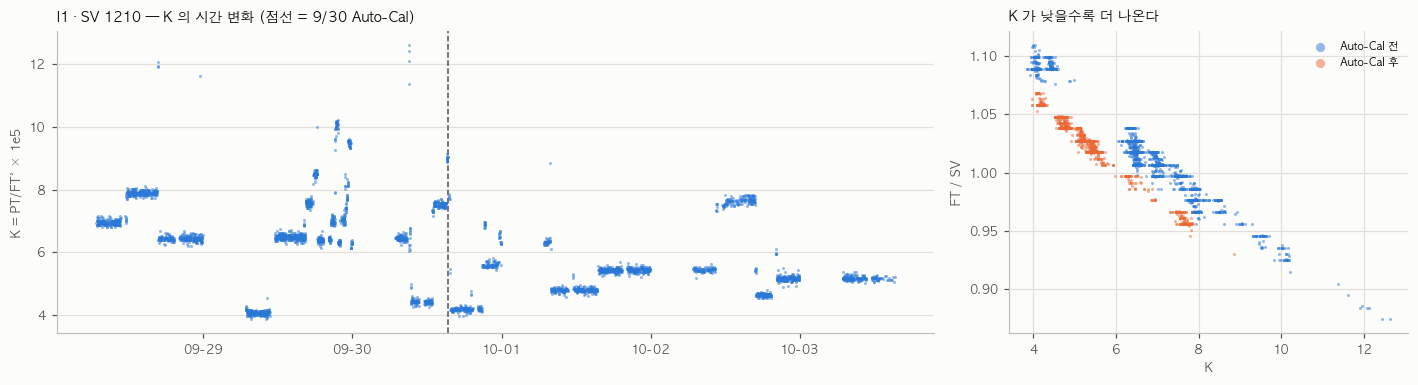

In [10]:
# I1 — K 가 몇 개 상태 사이를 오가고, FT/SV 가 그대로 따라간다
c = BL["I1"][0]
w = c[(c.t_start >= "2026-09-28") & (c.t_start < "2026-10-04")]
top = w.SV_class.value_counts().index[0]
w1 = w[w.SV_class == top]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), facecolor=SURFACE, gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
ax.scatter(w1.t_start, w1.K, s=4, color=BLUE, alpha=0.5, lw=0, zorder=3)
ax.axvline(pd.Timestamp("2026-09-30 15:27"), color=INK2, lw=1, ls="--")
style_ax(ax)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
ax.set_ylabel("K = PT/FT² × 1e5", color=INK2, fontsize=8)
ax.set_title(f"I1 · SV {top:.0f} — K 의 시간 변화 (점선 = 9/30 Auto-Cal)", loc="left", color=INK, fontsize=9, fontweight="bold")
ax = axes[1]
for (lo, hi), col, lab in [(("2026-09-28", "2026-09-30 15:27"), BLUE, "Auto-Cal 전"),
                           (("2026-09-30 15:27", "2026-10-04"), ORANGE, "Auto-Cal 후")]:
    q = w1[(w1.t_start >= lo) & (w1.t_start < hi)]
    ax.scatter(q.K, q.FT_SV, s=4, color=col, alpha=0.5, lw=0, label=lab, zorder=3)
style_ax(ax, grid="both")
ax.set_xlabel("K", color=INK2, fontsize=8)
ax.set_ylabel("FT / SV", color=INK2, fontsize=8)
ax.legend(fontsize=7, frameon=False, markerscale=3)
ax.set_title("K 가 낮을수록 더 나온다", loc="left", color=INK, fontsize=9, fontweight="bold")
fig.tight_layout()
plt.show()

K 가 **몇 개의 평탄한 수준(약 4 ~ 8) 사이를 계단으로, 하루에도 여러 번 오간다.** 연속적인 마모라면 이렇게 왔다 갔다 하지 않는다 —
**노즐·밸브처럼 상태가 몇 개뿐인 부품**이 원인이라는 I1 노트북의 결론과 맞는다. FT/SV 는 K 에 거의 결정적으로 묶여 있고(누설),
Auto-Cal 뒤에는 같은 K 에서 FT/SV 가 약 3~4% 낮은 선으로 옮겨 간다(Hz 표가 낮아졌으니까).

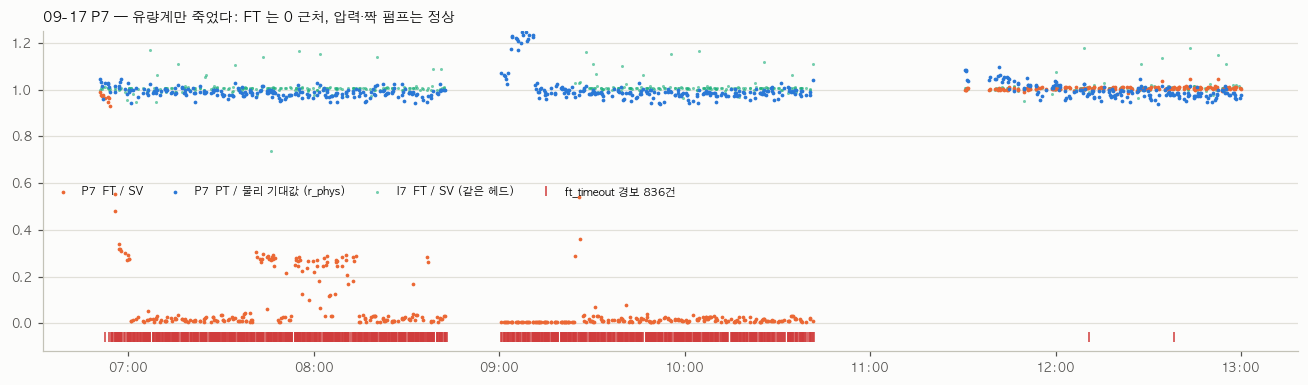

,구간,사이클,FT/SV 중앙,r_phys 중앙,펌프 잔차 중앙 %,I7 FT/SV
0,06:50~10:45,429,0.016,0.987,-98.409,1.007


In [11]:
# 실례 — 9/17 P7: FT 만 0 으로 떨어지고 압력은 그대로
c7 = BL["P7"][0]
w = c7[(c7.t_start >= "2026-09-17 05:00") & (c7.t_start < "2026-09-17 13:00")]
al = load_feat("P7", "alerts")
al = al[(al.time >= "2026-09-17 05:00") & (al.time < "2026-09-17 13:00")]
i7 = BL["I7"][0]
wi = i7[(i7.t_start >= "2026-09-17 05:00") & (i7.t_start < "2026-09-17 13:00")]

fig, ax = plt.subplots(figsize=(12, 3.6), facecolor=SURFACE)
ax.scatter(w.t_start, w.FT_SV, s=6, color=ORANGE, lw=0, label="P7  FT / SV", zorder=3)
ax.scatter(w.t_start, w.r_phys, s=6, color=BLUE, lw=0, label="P7  PT / 물리 기대값 (r_phys)", zorder=3)
ax.scatter(wi.t_start, wi.FT_SV, s=4, color=AQUA, lw=0, alpha=0.6, label="I7  FT / SV (같은 헤드)", zorder=2)
ax.plot(al.time, np.full(len(al), -0.06), "|", color=CRITICAL, ms=6, label=f"ft_timeout 경보 {len(al)}건")
style_ax(ax)
ax.set_ylim(-0.12, 1.25)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.legend(fontsize=7, frameon=False, ncol=4, loc="center left")
ax.set_title("09-17 P7 — 유량계만 죽었다: FT 는 0 근처, 압력·짝 펌프는 정상", loc="left", color=INK, fontsize=9, fontweight="bold")
fig.tight_layout()
plt.show()
pd.DataFrame({"구간": ["06:50~10:45"], "사이클": [int(((w.FT_SV < 0.5)).sum())],
              "FT/SV 중앙": [w[w.FT_SV < 0.5].FT_SV.median()], "r_phys 중앙": [w[w.FT_SV < 0.5].r_phys.median()],
              "펌프 잔차 중앙 %": [w[w.FT_SV < 0.5].pump_resid.median()], "I7 FT/SV": [wi.FT_SV.median()]}).round(3)

**9/17 P7 은 신호 표(I1 노트북 §8)의 "센서 고장" 행 그대로다.**

| 지표 | 값 | 해석 |
|---|---|---|
| FT/SV · 펌프 잔차 | 0.02 · −98% | FT 만 보면 펌프가 멈춘 것 |
| PT / 물리 기대값 (r_phys) | 0.98~1.00 | 압력은 평소 유량이 흐를 때 그대로 → **실제로는 나가고 있었다** |
| K (FT 로 계산) | 수만 % | FT 가 분모라 같이 터진다 — "두 지표가 고정 비율로 함께" |
| 짝 펌프 I7 | FT/SV 1.007 | 헤드·사출은 정상 |

- 06:50 부터 FT 가 몇 분에 걸쳐 1365 → 29 로 내려가 **약 4시간** 0 근처였고, 10:45~11:20 멈춘 뒤 정상으로 돌아왔다(수리로 추정).
- PLC 에는 유량 알람이 없어(I1 노트북 §8) 이 4시간을 아무도 몰랐을 수 있다. **개루프라 토출은 Hz 로 계속 정상**이었을 것 — 제품 영향은 적고, **보전 경보로는 바로 잡아야 할 이벤트**다.
- 우리 실시간 규칙 `ft_timeout` 은 그 사이 830여 번 울렸다 — 잡기는 잡는다. 다만 이 규칙은 평소에도 많이 울린다(§7).
- **진단 규칙으로 정리**: `FT/SV ↓↓` 이면서 `r_phys ≈ 1` → **유량계**. `FT/SV ↓` 이면서 `r_phys ↓` → 실제 토출 저하(펌프·흡입).

---
## §5. H4 — 기준선 형태: 폴리올은 Hz 2차식, ISO 는 누설식인가

REF 주(09-14~19)로 맞추고 **10-01~07 에 그대로 적용**해서 잔차의 퍼짐(1.4826·MAD)과 레시피 의존(η²)을 본다.
세 형태를 모든 펌프에 다 맞춰 본다.

- (A) 상수: FT/Hz = r
- (B) 폴리올형: FT/Hz = a + b·h + c·h² + d·(μ−1),  h = Hz/1000
- (C) ISO 누설형: FT/Hz = a + b·(PT/Hz·1000)/μ

In [12]:
def eta2(y, cls):
    y, cls = pd.Series(np.asarray(y, float)), pd.Series(np.asarray(cls))
    ok = y.notna()
    y, cls = y[ok], cls[ok]
    gm = y.mean()
    sst = ((y - gm) ** 2).sum()
    return sum(len(v) * (v.mean() - gm) ** 2 for _, v in y.groupby(cls)) / sst if sst > 0 else np.nan


def design(c, form):
    h, mu = c.Hz / 1000, c.mu_rel
    if form == "A":
        return np.ones((len(c), 1))
    if form == "B":
        return np.c_[np.ones(len(c)), h, h ** 2, mu - 1]
    return np.c_[np.ones(len(c)), (c.PT / c.Hz * 1000) / mu]


rows = []
for p in ORDER:
    c = CYC[p][(CYC[p].n_hz_levels == 1) & (CYC[p].FT > 0)]
    tr = c[(c.t_start >= REF[0]) & (c.t_start < REF[1])]
    te = c[(c.t_start >= "2026-10-01") & (c.t_start < "2026-10-08")]
    row = {"펌프": p, "원료형": PumpSetup(p, S, allow_unverified=True).material}
    for f in "ABC":
        coef, _ = _robust_lstsq(design(tr, f), tr.FT_Hz.to_numpy())
        res = (te.FT_Hz / (design(te, f) @ np.array(coef)) - 1) * 100
        row[f"{f} 퍼짐 %"] = 1.4826 * np.median(np.abs(res - res.median()))
        row[f"{f} η²"] = eta2(res, te.SV_class)
    row["가장 좁은 형태"] = min("ABC", key=lambda f: row[f"{f} 퍼짐 %"])
    rows.append(row)
H4 = pd.DataFrame(rows).set_index("펌프").round(3)
H4

,원료형,A 퍼짐 %,A η²,B 퍼짐 %,B η²,C 퍼짐 %,C η²,가장 좁은 형태
펌프,,,,,,,,
P1,POL,0.493,0.663,0.286,0.069,0.483,0.672,B
I1,ISO,1.501,0.195,1.086,0.054,0.541,0.054,C
P2,POL,0.485,0.572,0.495,0.226,0.592,0.562,A
I2,ISO,2.480,0.785,1.221,0.103,0.995,0.412,C
P3,POL,0.371,0.108,0.328,0.006,0.308,0.063,C
I3,ISO,0.097,0.183,0.130,0.260,0.125,0.004,A
P4,POL,0.114,0.186,0.094,0.174,0.109,0.186,B
I4,ISO,0.173,0.403,0.163,0.003,0.145,0.005,C
P5,POL,0.430,0.439,0.269,0.242,0.391,0.290,B


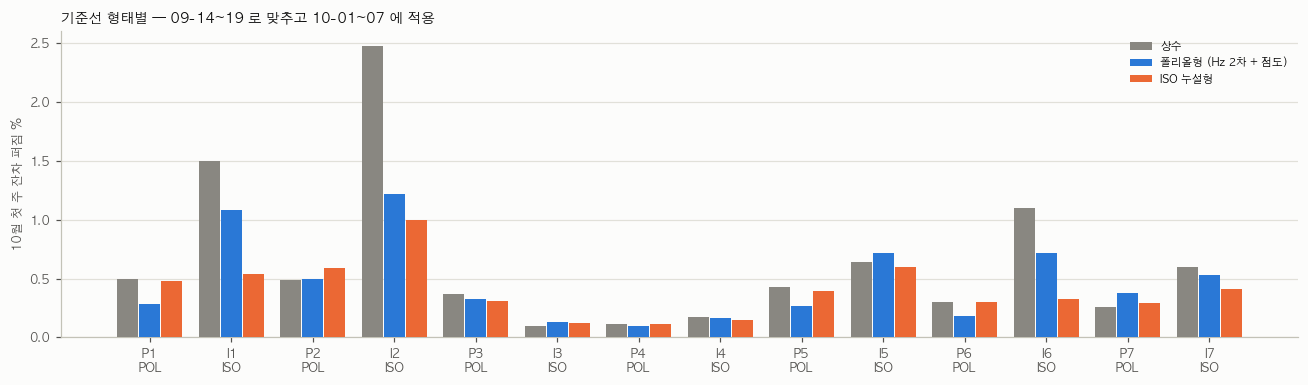

In [13]:
fig, ax = plt.subplots(figsize=(12, 3.6), facecolor=SURFACE)
x = np.arange(len(H4))
for k, (f, col, lab) in enumerate([("A", MUTED, "상수"), ("B", BLUE, "폴리올형 (Hz 2차 + 점도)"), ("C", ORANGE, "ISO 누설형")]):
    ax.bar(x + (k - 1) * 0.27, H4[f"{f} 퍼짐 %"], width=0.26, color=col, label=lab, zorder=3)
style_ax(ax)
ax.set_xticks(x, [f"{p}\n{H4.loc[p, '원료형']}" for p in H4.index], fontsize=8)
ax.set_ylabel("10월 첫 주 잔차 퍼짐 %", color=INK2, fontsize=8)
ax.legend(fontsize=7, frameon=False)
ax.set_title("기준선 형태별 — 09-14~19 로 맞추고 10-01~07 에 적용", loc="left", color=INK, fontsize=9, fontweight="bold")
fig.tight_layout()
plt.show()

**읽기 — 조건부 성립**

- **ISO 는 누설형(C)이 7대 중 6대에서 가장 좁다.** 압력이 크게 움직이는 펌프일수록 차이가 크다 —
  I1 1.50 → 0.54%, I2 2.48 → 1.00%, I6 1.10 → 0.33%. 노즐 상태가 바뀌어 PT 가 움직여도 누설식이 FT/Hz 를 따라간다.
  I3 은 셋 다 0.1% 대라 차이가 없다(압력 범위가 좁음).
- **폴리올형(B)은 퍼짐보다 레시피 의존(η²)에서 효과가 크다** — P1 0.66 → 0.07, P6 0.49 → 0.01, P2 0.57 → 0.23, P5 0.44 → 0.24.
  퍼짐만 보면 CUSH 두 대(P2·P7)는 상수(A)와 같거나 조금 낫다. P7 은 Hz 범위가 좁아(3525~4027) 2차항이 할 일이 없다.
- §1 의 FT/Hz 중앙이 0.25~0.84 로 펌프마다 다르다 — **펌프 기종(배제용적)·유량계 환산이 서로 다르다.**
  기준선은 반드시 **펌프별로** 맞추고, 펌프끼리 절댓값을 비교하면 안 된다.
- `PumpBaseline.fit` 은 원료형으로 B/C 를 고른다(폴리올 B, ISO C). 지금 결과로는 그대로 둬도 된다.

---
## §6. H5 — 온도(점도)로 원료의 정체를 알 수 있나

### 6-1. 원료표부터 — 출처 주의

`OJT/공정도.xls` 의 원료 점도표는 **2013년 북경공장** 자료다(시트 제목 "북경공장 탱크 재질…", 2013.5.12).
거기서 원료 조합은 BACK = TM-337 + TM-20, CUSH = AM-315 + MC-70, 고탄성 = MBR-360 + MC-70.
이 공장·지금 원료와 같다는 보장은 없다 — **데이터로 확인할 대상**이지 전제가 아니다.

### 6-2. 온도 범위 — B 를 데이터로 정할 수 있나

B 는 온도가 움직여야 보인다. 펌프별 사이클 온도(1~99%)와, 누설식 / 압력식의 B 프로파일(잔차제곱합이 최소의 1.01배 안인 B 범위).

In [14]:
Bs = np.arange(0, 12001, 250.0)


def b_profile(c, kind):
    """ISO: FT/Hz = a + b·(PT/Hz)/μ(B),   POL: PT = c0 + R·μ(B)·FT_e + K·FT_e²  — B 별 상대 SSE."""
    sse = []
    for B in Bs:
        mu = mu_rel(c.T_C, B, 22.0)
        if kind == "ISO":
            X, y = np.c_[np.ones(len(c)), (c.PT / c.Hz * 1000) / mu], c.FT_Hz.to_numpy()
        else:
            fte = c.Hz * np.median(c.FT / c.Hz)
            X, y = np.c_[np.ones(len(c)), mu * fte, fte ** 2], c.PT.to_numpy()
        r = y - X @ np.linalg.lstsq(X, y, rcond=None)[0]
        sse.append((r ** 2).sum())
    return np.array(sse) / min(sse)


def pct_per_C(B, T=22.0):
    return (1 - mu_rel(T + 1, B, T)) * 100


rows, PROF = [], {}
for p in ORDER:
    st = PumpSetup(p, S, allow_unverified=True)
    c = CYC[p][(CYC[p].n_hz_levels == 1) & (CYC[p].FT > 0)].dropna(subset=["T_C"])
    pr = b_profile(c, st.material)
    PROF[p] = pr
    ok = Bs[pr < 1.01]
    rows.append({"펌프": p, "탱크": S["pumps"][p]["tank"], "설정 원료": st.material_name,
                 "T 1~99% ℃": f"{c.T_C.quantile(.01):.1f}~{c.T_C.quantile(.99):.1f}",
                 "B 최적": Bs[pr.argmin()], "B 1% 범위": f"{ok.min():.0f}~{ok.max():.0f}",
                 "%/℃": round(pct_per_C(Bs[pr.argmin()]), 2), "설정 B": st.B,
                 "식별": "가능" if ok.max() - ok.min() <= 2000 and ok.min() > 0 else "불가"})
H5 = pd.DataFrame(rows).set_index("펌프")
H5

,탱크,설정 원료,T 1~99% ℃,B 최적,B 1% 범위,%/℃,설정 B,식별
펌프,,,,,,,,
P1,P1,TM-337,19.4~23.7,9250.0,2500~12000,10.04,5756.0,불가
I1,I1,TM-20,20.1~24.1,1000.0,750~1500,1.14,1921.0,가능
P2,P5,AM-315,17.5~23.7,0.0,0~750,0.00,5418.0,불가
I2,I3,ISO-GENERIC,19.6~21.9,0.0,0~0,0.00,2351.0,불가
P3,P2,POL-GENERIC,21.9~24.0,0.0,0~250,0.00,5511.0,불가
I3,I2,ISO-GENERIC,21.8~23.3,750.0,0~3000,0.85,2351.0,불가
P4,P4,POL-GENERIC,22.0~23.3,0.0,0~250,0.00,5511.0,불가
I4,I2,ISO-GENERIC,21.8~23.3,0.0,0~250,0.00,2351.0,불가
P5,P3,MBR-360,20.3~23.6,5000.0,500~12000,5.56,5360.0,불가


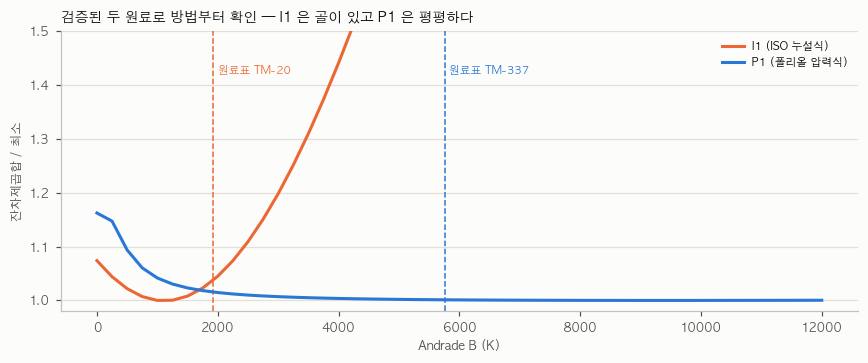

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.4), facecolor=SURFACE)
ax.plot(Bs, PROF["I1"], color=ORANGE, lw=2, label="I1 (ISO 누설식)", zorder=3)
ax.plot(Bs, PROF["P1"], color=BLUE, lw=2, label="P1 (폴리올 압력식)", zorder=3)
ax.axvline(S["materials"]["TM-20"]["B"], color=ORANGE, lw=1, ls="--")
ax.axvline(S["materials"]["TM-337"]["B"], color=BLUE, lw=1, ls="--")
ax.text(S["materials"]["TM-20"]["B"] + 80, 1.42, "원료표 TM-20", color=ORANGE, fontsize=7)
ax.text(S["materials"]["TM-337"]["B"] + 80, 1.42, "원료표 TM-337", color=BLUE, fontsize=7)
style_ax(ax)
ax.set_ylim(0.98, 1.5)
ax.set_xlabel("Andrade B (K)", color=INK2, fontsize=8)
ax.set_ylabel("잔차제곱합 / 최소", color=INK2, fontsize=8)
ax.legend(fontsize=7, frameon=False, loc="upper right")
ax.set_title("검증된 두 원료로 방법부터 확인 — I1 은 골이 있고 P1 은 평평하다", loc="left", color=INK, fontsize=9, fontweight="bold")
fig.tight_layout()
plt.show()

**읽기**

- **탱크 온도가 1.5~6℃ 폭(대부분 2~4℃)으로 관리되고 있다.** 그 안에서 점도 변화는 폴리올 약 ±10~15%, ISO 약 ±4% 뿐이다.
- 방법 검증: **I1 은 B ≈ 1000 (750~1500)** — 원료표 TM-20(1921) 과 같은 자릿수지만 조금 작다. 골이 분명해서 **ISO 누설식으로는 B 가 정해진다**.
  **P1 은 골이 거의 평평하다** — 폴리올 압력에서 온도 효과(±10% × 점성분 약 25%)가 배관 상태 변화(±2~5%)에 묻힌다.
- 다른 펌프는 대부분 "불가" — 온도 폭이 더 좁거나(HD2 1.5℃), 펌프 압력 범위가 좁아 누설식 자체가 약하다.
- **결론: 지금 데이터의 온도 변화로는 원료 이름을 가를 수 없다.** 가르려면 온도가 크게 움직이는 구간(연휴 뒤 재가동, 9/27 같은 날)을
  일부러 모으거나, 현장에서 탱크 시료 점도를 한 번 재는 것이 빠르다.

### 6-3. 같은 기종끼리 누설 비교 — I1 vs I2

누설은 압력/점도에 비례한다. **배제용적(절편 a)이 같은 펌프끼리**는 누설 기울기 비 = 점도의 역비(마모가 같다면)다.
ISO 펌프 중 절편이 같은 건 **I1(0.426) · I2(0.424)** 뿐이다 — I3~I7 은 기종이 다르다.

In [16]:
rows = []
for p in ["I1", "I2", "I3", "I4", "I5", "I6", "I7"]:
    c = CYC[p][(CYC[p].n_hz_levels == 1) & (CYC[p].FT > 0)].copy()
    c["x"] = c.PT / c.Hz * 1000
    b, a = np.polyfit(c.x, c.FT_Hz, 1)
    wk = {}
    for w, g in c.groupby(c.t_start.dt.to_period("W-SUN")):
        if len(g) > 500 and g.x.std() > 0.5:
            bw, aw = np.polyfit(g.x, g.FT_Hz, 1)
            wk[str(w.start_time.date())[5:]] = round(-bw / aw * 1000, 2)
    rows.append({"펌프": p, "탱크": S["pumps"][p]["tank"], "절편 a (배제)": round(a, 3),
                 "누설 k = −b/a (×1e-3)": round(-b / a * 1000, 2), "상관 r": round(np.corrcoef(c.x, c.FT_Hz)[0, 1], 2),
                 "PT/Hz 5~95%": f"{c.x.quantile(.05):.1f}~{c.x.quantile(.95):.1f}", "주별 k": wk})
SLIP = pd.DataFrame(rows).set_index("펌프")
SLIP

,탱크,절편 a (배제),누설 k = −b/a (×1e-3),상관 r,PT/Hz 5~95%,주별 k
펌프,,,,,,
I1,I1,0.426,7.66,-0.93,20.1~28.5,"{'09-07': 6.53, '09-14': 6.89, '09-21': 5.66, ..."
I2,I3,0.424,14.30,-0.93,17.4~20.9,"{'09-07': 13.73, '09-14': 14.12, '09-21': 13.7..."
I3,I2,0.436,1.09,-0.54,11.9~14.1,"{'09-07': 0.54, '09-14': 0.99, '09-21': 1.28, ..."
I4,I2,0.410,1.77,-0.72,22.7~24.5,"{'09-07': 1.96, '09-14': 1.7, '10-05': 1.79}"
I5,I3,0.293,3.89,-0.29,13.6~17.5,"{'09-07': 4.34, '09-14': 4.4, '09-21': 3.62, '..."
I6,I1,0.324,4.05,-0.94,18.6~29.7,"{'09-07': 4.1, '09-14': 4.09, '09-21': 3.28, '..."
I7,I3,0.268,3.58,-0.07,12.2~16.5,"{'09-07': 3.47, '09-14': -1.15, '09-21': 3.94,..."


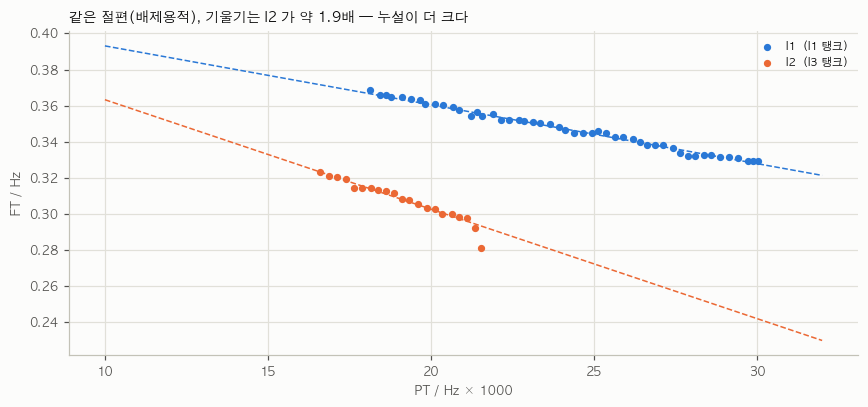

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.8), facecolor=SURFACE)
for p, col in [("I1", BLUE), ("I2", ORANGE)]:
    c = CYC[p][(CYC[p].n_hz_levels == 1) & (CYC[p].FT > 0)].copy()
    c["x"] = c.PT / c.Hz * 1000
    bins = pd.cut(c.x, np.arange(c.x.quantile(.01), c.x.quantile(.99), 0.25))
    g = c.groupby(bins, observed=True).agg(x=("x", "median"), y=("FT_Hz", "median"), n=("x", "size"))
    g = g[g.n >= 50]
    ax.scatter(g.x, g.y, s=14, color=col, zorder=3, label=f"{p}  ({S['pumps'][p]['tank']} 탱크)")
    b, a = np.polyfit(c.x, c.FT_Hz, 1)
    xx = np.linspace(10, 32, 50)
    ax.plot(xx, a + b * xx, color=col, lw=1, ls="--", zorder=2)
style_ax(ax, grid="both")
ax.set_xlabel("PT / Hz × 1000", color=INK2, fontsize=8)
ax.set_ylabel("FT / Hz", color=INK2, fontsize=8)
ax.legend(fontsize=7, frameon=False)
ax.set_title("같은 절편(배제용적), 기울기는 I2 가 약 1.9배 — 누설이 더 크다", loc="left", color=INK, fontsize=9, fontweight="bold")
fig.tight_layout()
plt.show()

**읽기**

- I1 과 I2 는 **배제용적이 같다**(절편 0.426 / 0.424) — 같은 기종으로 본다. 단 절편은 PT=0 까지 외삽한 값이라(측정 범위 PT/Hz 17~30) 몇 % 의 불확실성은 있다.
  기울기 비 k = −b/a 는 FT 환산계수가 달라도 변하지 않는 양이라 유량계 차이에는 영향받지 않는다.
- 누설 기울기는 **I2 가 I1 의 약 1.9배**이고 주별로 봐도 일정하다. 원인은 둘 중 하나다:
  1. **Tank 3 ISO 가 TM-20 보다 묽다** (점도 약 1/1.9 → 약 2.5 cP 대, 같은 마모라면). TDI 계열 단독 원료가 이 정도 점도다.
  2. **I2 펌프가 더 닳았다** (같은 원료라도 틈새가 넓으면 누설↑).
- 2013 원료표대로 Tank 3 ISO 가 **MC-70(점도 TM-20 의 약 2.3배)** 이라면 기울기는 I1 의 **0.4배**여야 한다 — **반대 방향이다.**
  → "Tank 3 ISO = MC-70" 은 데이터와 맞지 않는다. 설정(`ISO-GENERIC`)을 MC-70 으로 바꾸지 않는다.
- 주별 기울기가 4주 동안 거의 안 변하므로 마모가 빠르게 진행 중이지는 않다. 원료 차이인지 마모 차이인지는 **Tank 3 ISO 의 MSDS / 시료 점도 한 번**이면 끝난다.

### 6-4. 헤드별 ISO/POL 비 — 같은 원료 계통끼리 일치하나

같은 순간의 POL·ISO 사이클을 짝지어(시작 시각 1초 이내) **SV 비**와 **FT 비**를 본다.
같은 원료 탱크를 쓰는 헤드끼리는 비율 분포도 비슷해야 한다.

In [18]:
rows = []
for k in range(1, 8):
    P = load_feat(f"P{k}")[["t_start", "SV_class", "FT"]].sort_values("t_start")
    I = load_feat(f"I{k}")[["t_start", "SV_class", "FT"]].sort_values("t_start")
    m = pd.merge_asof(P, I, on="t_start", tolerance=pd.Timedelta("1s"), direction="nearest", suffixes=("_P", "_I")).dropna()
    r = m.SV_class_I / m.SV_class_P
    rows.append({"헤드": f'{S["pumps"][f"P{k}"]["head"]}/{S["pumps"][f"P{k}"]["slot"]}',
                 "폴리올 (탱크)": f'P{k} {S["pumps"][f"P{k}"]["name"].split()[-1]} ({S["pumps"][f"P{k}"]["tank"]})',
                 "ISO (탱크)": f'I{k} ({S["pumps"][f"I{k}"]["tank"]})', "짝 사이클": len(m),
                 "ISO/POL SV비 5%": r.quantile(.05), "중앙": r.median(), "95%": r.quantile(.95),
                 "FT비 중앙": (m.FT_I / m.FT_P).median()})
RATIO = pd.DataFrame(rows).set_index("헤드").round(3)
RATIO

,폴리올 (탱크),ISO (탱크),짝 사이클,ISO/POL SV비 5%,중앙,95%,FT비 중앙
헤드,,,,,,,
HD1/1,P1 BACK (P1),I1 (I1),59494,0.428,0.474,0.535,0.487
HD1/2,P2 CUSH (P5),I2 (I3),59922,0.387,0.480,0.521,0.482
HD2/1,P3 SOFT (P2),I3 (I2),8185,0.387,0.406,0.443,0.407
HD2/2,P4 HARD (P4),I4 (I2),5813,0.505,0.558,0.561,0.562
HD3/1,P5 고탄성 (P3),I5 (I3),21299,0.320,0.329,0.435,0.335
HD3/2,P6 BACK (P1),I6 (I1),9450,0.432,0.463,0.543,0.461
HD4/1,P7 CUSH (P5),I7 (I3),67486,0.446,0.488,0.531,0.491


**읽기**

- **BACK** 두 헤드(HD1/1 P1·I1, HD3/2 P6·I6 — 같은 P1·I1 탱크): **0.47 / 0.46**.
- **CUSH** 두 헤드(HD1/2 P2·I2, HD4/1 P7·I7 — 같은 P5·I3 탱크): **0.48 / 0.49**.
- 고탄성(HD3/1, P3 탱크 + Tank 3 ISO) **0.33**, SOFT(HD2/1) 0.41, HARD(HD2/2) 0.56 — 각각 다른 계통.
- topology 의 탱크 공유 관계와 비율이 **정확히 맞는다** → 펌프-탱크 매핑(설정)은 데이터로 확인됐다.
- 다만 SG 설정이 폴리올 1.03 · ISO 1.20 으로 전부 같아서(I1 노트북 §11-7 계열 확인) FT 는 원료별 실제 비중을 반영하지 않는다 — 비율만으로 원료 이름은 못 정한다.

### 6-5. 탱크별 정리

| 탱크 | 쓰는 펌프 | 이름(topology) | 데이터가 말하는 것 | 원료 |
|---|---|---|---|---|
| P1 | P1, P6 | BACK | 헤드비 0.47/0.46 일치. 점도 B 는 식별 불가(P1 골 평평) | TM-337 **(검증 — 기존)** |
| I1 | I1, I6 | ISO | B ≈ 1000 (750~1500) — TM-20(1921) 과 같은 자릿수 | TM-20 **(검증 — 기존)** |
| P5 | P2, P7 | CUSH | 헤드비 0.48/0.49 일치 | AM-315 (이름 기준, 미검증) |
| I3 (Tank 3 ISO) | I2, I5, I7 | ISO | **I2 누설이 같은 기종 I1 의 1.9배 → TM-20 보다 묽거나 I2 마모. MC-70(2013 원료표)과는 반대** | **미상** — MSDS 확인 필요 |
| P3 | P5 | 고탄성 | 헤드비 0.33 | MBR-360 (이름 기준, 미검증) |
| P2 | P3 | SOFT | HD2 다단 사출, 헤드비 0.41 | 미상 |
| P4 | P4 | HARD | 헤드비 0.56 | 미상 |
| I2 (Tank 2-2 MDI) | I3, I4 | MDI | 유량계가 다르다(Imp/L 16384 vs 20480). 누설 기울기 I1 의 1/5~1/7 (기종도 달라 직접 비교는 불가) | MDI 계열 (이름 기준) |

---
## §7. 실시간 경보 — `ft_timeout` 은 지금 기준으로 쓸 수 있나

`ft_timeout` = 켜진 뒤 3초 안에 FT 가 SV ±3% 에 못 들어오면 1회. 개루프라 FT/SV 가 ±수% 어긋나 있는 펌프에선 **정상일 때도** 울린다.

In [19]:
rows = []
for p in ORDER:
    a = load_feat(p, "alerts")
    c = load_feat(p)
    nd = c.t_start.dt.normalize().nunique()
    n = (a.type == "ft_timeout").sum() if len(a) else 0
    rows.append({"펌프": p, "ft_timeout 합": n, "생산일당": round(n / nd, 1), "사이클 대비 %": round(n / len(c) * 100, 2),
                 "FT/SV 중앙": round(c.FT_SV.median(), 3),
                 "|FT/SV−1| > 3% 사이클 %": round(((c.FT_SV - 1).abs() > 0.03).mean() * 100, 1),
                 "r_early": (a.type == "r_early").sum() if len(a) else 0})
ALR = pd.DataFrame(rows).set_index("펌프")
ALR

,ft_timeout 합,생산일당,사이클 대비 %,FT/SV 중앙,|FT/SV−1| > 3% 사이클 %,r_early
펌프,,,,,,
P1,2,0.1,0.00,0.992,0.0,0
I1,9246,420.3,15.54,1.021,27.3,0
P2,15178,689.9,25.03,0.994,24.0,0
I2,3009,136.8,4.99,1.004,8.4,0
P3,126,6.0,1.54,1.000,0.7,0
I3,139,6.6,1.70,0.997,0.0,0
P4,0,0.0,0.00,0.990,0.0,0
I4,0,0.0,0.00,0.999,0.0,0
P5,22,1.0,0.09,0.995,0.2,0


**읽기**

- 경보 수는 **그 펌프의 FT/SV 가 평소 ±3% 밖에 얼마나 있느냐**로 거의 정해진다. I1(노즐 상태에 따라 FT/SV 1.00~1.10)·P2 가 대표적.
  이대로면 9/17 P7 같은 진짜 고장 834건이 평소 소음 수백 건/일 속에 묻힌다.
- 고칠 방향(now_vis §7 의 "짧은 창은 최근 기준" 과 같은 결론):
  1. 목표를 SV 가 아니라 **최근 기준(EWMA) 대비**로 — "평소의 이 펌프" 에서 벗어날 때만.
  2. **두 지표 서명**으로 묶기 — FT 저하 + r_phys 정상 = 유량계(§4), FT 저하 + r_phys 저하 = 토출 저하.
- `r_early`(1.6초 시점 FT/기대 < 0.7) 는 기준선이 있어야 계산돼서, 기준선 없이 만든 이번 빌드에서는 0건이다 — 기준선을 붙인 뒤 0.7 재검증이 남아 있다.

---
## §8. 종합

| 가설 | 판정 | 한 줄 |
|---|---|---|
| H1 Hz/SV 는 Auto-Cal 때만 | **성립** | 14대 × 4주, Auto-Cal 날 외 0%. I3 의 레시피 단위 미세 조정만 예외 |
| H2 Auto-Cal 은 펌프값을 안 바꾼다 | **성립 + 보강** | Auto-Cal = 지금 FT/SV 를 1 로. 폴리올은 FT/SV 가 Hz 를 따라가고, ISO 는 **배관 변화를 Hz 로 흡수**. P2 의 +0.9% FT/Hz 는 보류 |
| H3 배관·펌프 분리 | **성립** | K ±10~50% 움직여도 펌프 잔차 일별 ±1.4%. 유량계 고장 실례(9/17 P7) |
| H4 기준선 형태 | **조건부** | ISO 누설식·폴리올 2차식 유효. 펌프마다 기종이 달라 펌프별 학습 필수 |
| H5 점도로 원료 판별 | **부분** | B 는 I1 만 식별. Tank 3 ISO ≠ MC-70(2013) 쪽 증거. 탱크-펌프 매핑은 확인 |

**모델링에 가져갈 것**

1. 기준선은 **펌프별 · 주된 안정 출처(`steady_src`)별**로 학습. HD2 는 다단(`n_hz_levels`)을 따로 다룰 것.
2. 학습 구간에서 **Auto-Cal / 레시피 Gain 변경 시점**(H1 방법으로 데이터에서 검출)을 경계로 표시 — 기준선(Hz 기준)은 그대로 쓰지만 FT/SV 계열 피처는 구간이 끊긴다.
3. Auto-Cal 직후 FT/SV ≈ 1 은 정상의 증거가 아니다 — **ISO 는 K·Hz/SV 변화량을 같이** 피처로.
4. 실시간 규칙은 **최근 기준 + 두 지표 서명**으로 다시 짠다(§7).
5. 이상 사례 라벨 후보: 9/17 P7 유량계(06:50~10:45), I1 노즐 상태 전환(9/28~10/3), I7 K 계단(9/21~).

**현장에 물어볼 것**

- Tank 3 ISO(I2·I5·I7) 와 SOFT·HARD·MDI 탱크의 **현재 원료명 / MSDS 점도**
- 9/17 오전 P7 유량계 조치 이력, 9/21 무렵 I7 라인(노즐) 작업 여부
- 10/5 P2·I2 Auto-Cal 전후에 한 작업(필터·탈기 등)